<a href="https://colab.research.google.com/github/Kasera001/Data-Science-projects/blob/main/F1_Grand_Prix_Prediction/fastf1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install fastf1

In [ ]:
# first set up the cache
import sys
print(sys.executable)
import fastf1
print(fastf1.__version__)

import os
import fastf1
import pandas as pd
os.makedirs('f1_cache', exist_ok=True) # creating a folder that store the cached data
fastf1.Cache.enable_cache('f1_cache')


/usr/bin/python3
3.9.0


/usr/local/lib/python3.13/dist-packages/fastf1/req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


In [ ]:
# loading one race
def load_race(year,round_number):
    session = fastf1.get_session(year,round_number,"R")
    session.load(laps=False,telemetry=False,weather=False,messages=False)
    df = session.results[['Abbreviation','TeamName','GridPosition','Position']].copy()
    df['year']= year
    df['round']=round_number
    df['race_name'] = session.event['EventName']
    return df
load_race(2025,1).head()
# finding the races to load
races =[]
for year in [2025,2026]:
    schedule = fastf1.get_event_schedule(year,include_testing=False)
    schedule = schedule[schedule['EventDate'] < pd.Timestamp.now()]
    for rnd in schedule['RoundNumber']:
        races.append((year,rnd))
print(len(races),races[:3],races[-3:])

#load all the races
all_results = []
for year, rnd in races:
    try:
       all_results.append(load_race(year, rnd))
       print('loaded', year, rnd)
    except Exception as e:
        print('FAILED',year,rnd,e)
data = pd.concat(all_results, ignore_index=True)
print(data.shape)
data.head()
data.tail()





core           INFO 	Loading data for Australian Grand Prix - Race [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Australian Grand Prix - Race [v3.9.0]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
INFO:fastf1.f1account:Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
DEBUG:fastf1.fastf1.req:Falling back to https://livetiming-mirror.fastf1.dev/static/2025/2025-03-16_Australian_Grand_Prix/2025-03-16_Race/SessionInfo.jsonStream
logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info da

42 [(2025, 1), (2025, 2), (2025, 3)] [(2026, 16), (2026, 17), (2026, 18)]


DEBUG:fastf1.fastf1.req:Falling back to https://livetiming-mirror.fastf1.dev/static/2025/2025-03-16_Australian_Grand_Prix/2025-03-16_Race/SessionInfo.jsonStream
logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in session

loaded 2025 1


logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in session_info
    raise SessionNotAvailableError(
    ...<2 lines>...
    )
fastf1._api.SessionNotAvailableError: No data for this session! If this session only finished

...

logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in session_info
    raise SessionNotAvailableError(
    ...<2 lines>...
    )
fastf1._api.SessionNotAvailableError: No data for this session! If this session only finished

loaded 2026 17


logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in session_info
    raise SessionNotAvailableError(
    ...<2 lines>...
    )
fastf1._api.SessionNotAvailableError: No data for this session! If this session only finished

loaded 2026 18
(853, 7)


,Abbreviation,TeamName,GridPosition,Position,year,round,race_name
848,ALB,Williams,16.0,18.0,2026,17,Singapore Grand Prix
849,BOT,Cadillac F1 Team,18.0,19.0,2026,17,Singapore Grand Prix
850,STR,Aston Martin,21.0,20.0,2026,17,Singapore Grand Prix
851,COL,Alpine F1 Team,15.0,21.0,2026,17,Singapore Grand Prix
852,BOR,Audi,14.0,22.0,2026,17,Singapore Grand Prix


In [ ]:
# finding the number of  races for the 2025 and 2026 season
print(data.groupby('year')['round'].unique()) # the number of races per season
print(data.groupby(['year','round']).size().value_counts()) # number of drivers per race


# check for any missing values
print(data.isna().sum())
print((data['GridPosition'] == 0)) #pit lane starts of every driver


# check the last race in 2026
data[data['year'] == 2026].tail(22)

#create the podium column and change the positions <= 3 to 0 and 1
#astype changes true or false to 1 and 0 res
data['podium'] = (data['Position'] <= 3).astype(int)

print(data[['Abbreviation', 'Position', 'podium']].head(8))
print(data['podium'].value_counts())
print(data['podium'].mean())

#the race with only 19 players
counts = data.groupby(['year', 'round', 'race_name']).size()
print(counts[counts == 19])



year
2025    [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...
2026    [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...
Name: round, dtype: object
20    23
22    17
19     1
Name: count, dtype: int64
Abbreviation    0
TeamName        0
GridPosition    0
Position        0
year            0
round           0
race_name       0
dtype: int64
0      False
1      False
2      False
3      False
4      False
       ...  
848    False
849    False
850    False
851    False
852    False
Name: GridPosition, Length: 853, dtype: bool
  Abbreviation  Position  podium
0          NOR       1.0       1
1          VER       2.0       1
2          RUS       3.0       1
3          ANT       4.0       0
4          ALB       5.0       0
5          STR       6.0       0
6          HUL       7.0       0
7          LEC       8.0       0
podium
0    730
1    123
Name: count, dtype: int64
0.14419695193434937
year  round  race_name         
2025  9      Spanish Grand Prix    19
dtype: int64


In [24]:
# adding the qualification data and the weather data to see how it affects the prix winner
def load_race_qualification(year, round_number):
    q = fastf1.get_session(year, round_number, "Q") #Qloads qualification
    q.load(laps=False, telemetry=False, weather=True, messages=False)
    res = q.results[['Abbreviation','Position','Q1','Q2','Q3']].copy()
    res = res.rename(columns ={'Position':'quali_pos'})
    res['best_q'] = res[['Q1','Q2','Q3']].min(axis=1) # takes the fastest
    # substract the pole time from everyone and converts time difference to seconds
    res['quali_gap'] = (res['best_q'] - res['best_q'].min()).dt.total_seconds()

    weather = q.weather_data
    res['q_track_temp'] = weather['TrackTemp']
    res['q_air_temp'] = weather['AirTemp']
    res['q_rain'] = int(weather['Rainfall'].any())
    res['year'] = year
    res['round'] = round_number
    res['race_name'] = q.event['EventName']
    return res.drop(columns=['Q1','Q2','Q3','best_q']) # the drop removes helper columns we do not need

# Alias the function so that load_quali also works
load_quali = load_race_qualification

In [25]:
# qualification rows in a loop using try and accept so that one failure does
# not stop the code

quali_rows = []
for y, r in races:
    try:
        # Using load_quali which is now aliased to load_race_qualification
        quali_rows.append(load_quali(y, r))
        print('quali loaded', y, r)
    except Exception as e:
        print('QUALI FAILED', y, r, e)

if len(quali_rows) > 0:
    quali = pd.concat(quali_rows, ignore_index=True)
    data = data.merge(quali, on=['year', 'round', 'Abbreviation'], how='left')
    data.to_csv('f1_results.csv', index=False) # so we do not have to load the data again and again
else:
    print("No qualification data was successfully loaded to concatenate.")

core           INFO 	Loading data for Australian Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Australian Grand Prix - Qualifying [v3.9.0]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
INFO:fastf1.f1account:Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
DEBUG:fastf1.fastf1.req:Falling back to https://livetiming-mirror.fastf1.dev/static/2025/2025-03-16_Australian_Grand_Prix/2025-03-15_Qualifying/SessionInfo.jsonStream
logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure 

QUALI FAILED 2025 1 The data you are trying to access has not been loaded yet. See `Session.load`


logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in session_info
    raise SessionNotAvailableError(
    ...<2 lines>...
    )
fastf1._api.SessionNotAvailableError: No data for this session! If this session only finished

QUALI FAILED 2025 2 The data you are trying to access has not been loaded yet. See `Session.load`


logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in session_info
    raise SessionNotAvailableError(
    ...<2 lines>...
    )
fastf1._api.SessionNotAvailableError: No data for this session! If this session only finished

...

QUALI FAILED 2026 15 The data you are trying to access has not been loaded yet. See `Session.load`


DEBUG:fastf1.fastf1.req:Falling back to https://livetiming-mirror.fastf1.dev/static/2026/2026-10-04_Bahrain_Grand_Prix/2026-10-03_Qualifying/SessionInfo.jsonStream
logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in sess

QUALI FAILED 2026 16 The data you are trying to access has not been loaded yet. See `Session.load`


DEBUG:fastf1.fastf1.req:Falling back to https://livetiming-mirror.fastf1.dev/static/2026/2026-10-11_Singapore_Grand_Prix/2026-10-10_Qualifying/SessionInfo.jsonStream
core           INFO 	Loading data for United States Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for United States Grand Prix - Qualifying [v3.9.0]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...


QUALI FAILED 2026 17 any API: 500 calls/h
QUALI FAILED 2026 18 any API: 500 calls/h
No qualification data was successfully loaded to concatenate.


In [50]:
# Feature engineering

print((data['GridPosition'] == 0).sum())

# find the pit lane  counts for the drivers
data = data.sort_values(['year','round']).reset_index(drop=True)
data['grid'] = data['GridPosition']
back = data.groupby(['year','round'])['grid'].transform('max')+1 # gives the races  a max grid position
data.loc[data['grid'] == 0, 'grid'] = back # overrides where the mask is true

# the drivers form (corrected by moving .mean() inside the rolling window calculation)
data['driver_podium_rate_5'] = (data.groupby('Abbreviation')['podium']
                               .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()))

# one row per team race
# the number of podiums the team scored and the teams average qualifying gap to pole (safely handling missing 'quali_gap')
#avoid team mate trap
if 'quali_gap' in data.columns:
    team_race = (data.groupby(['year','round','TeamName'], as_index=False)
                 .agg(team_podiums=('podium', 'sum'), team_gap=('quali_gap', 'mean')))
else:
    print("Warning: 'quali_gap' not found in data because qualification data loading failed. Omitting team_gap.")
    team_race = (data.groupby(['year','round','TeamName'], as_index=False)
                 .agg(team_podiums=('podium', 'sum')))

# group by team and year so 2026 rules reset starts every teams history again
# recent form without leakage
g =  team_race.groupby(['TeamName','year'])
team_race['team_podium_rate_5'] = g['team_podiums'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

if 'team_gap' in team_race.columns:
    team_race['team_gap_5'] = g['team_gap'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
else:
    print("Warning: 'team_gap' not calculated because qualification data was missing.")

# Dynamically select columns that actually exist to avoid KeyErrors during merge
merge_cols = ['year', 'round', 'TeamName', 'team_podiums', 'team_podium_rate_5']
if 'team_gap_5' in team_race.columns:
    merge_cols.append('team_gap_5')

# To prevent MergeErrors on re-running, clean up previously merged columns from 'data' first
existing_cols_to_drop = [col for col in merge_cols if col not in ['year', 'round', 'TeamName'] and col in data.columns]
if existing_cols_to_drop:
    data = data.drop(columns=existing_cols_to_drop)

# attach team features back to each driver
data = data.merge(team_race[merge_cols], on=['year','round','TeamName'], how='left')
data.to_csv('f1_results.csv', index=False)
print(data.columns.tolist())

# the track circuits
print(data['race_name'].unique())
STREET = ['Monaco Grand Prix', 'Singapore Grand Prix', 'Azerbaijan Grand Prix']
data['is_street'] = data['race_name'].isin(STREET).astype(int)

# a driver with no qualification gets slowest gap in race (safely guarded against missing quali_gap)
#it uses only the saturday dataso it does not lea
if 'quali_gap' in data.columns:
    by_race = data.groupby(['year','round'])['quali_gap']
    data['quali_gap'] = data['quali_gap'].fillna(by_race.transform('max'))
else:
    print("Warning: Skipping 'quali_gap' fillna because qualification column does not exist.")

# columns that still have gaps
print(data.isna().sum())
print(data[data['Abbreviation'] == 'VER']
      [['year', 'round', 'podium', 'driver_podium_rate_5', 'team_podium_rate_5']].head(8))

# clean up previous run legacy column versions if they still exist
legacy_cols = [c for c in data.columns if '-' in c or '_x' in c or '_y' in c]
if legacy_cols:
    data = data.drop(columns=legacy_cols)
print(data.columns.tolist())


0
['Abbreviation', 'TeamName', 'GridPosition', 'Position', 'year', 'round', 'race_name', 'podium', 'grid', 'is_street', 'driver_podium_rate_5', 'team_podiums', 'team_podium_rate_5']
['Australian Grand Prix' 'Chinese Grand Prix' 'Japanese Grand Prix'
 'Bahrain Grand Prix' 'Saudi Arabian Grand Prix' 'Miami Grand Prix'
 'Emilia Romagna Grand Prix' 'Monaco Grand Prix' 'Spanish Grand Prix'
 'Canadian Grand Prix' 'Austrian Grand Prix' 'British Grand Prix'
 'Belgian Grand Prix' 'Hungarian Grand Prix' 'Dutch Grand Prix'
 'Italian Grand Prix' 'Azerbaijan Grand Prix' 'Singapore Grand Prix'
 'United States Grand Prix' 'Mexico City Grand Prix'
 'São Paulo Grand Prix' 'Las Vegas Grand Prix' 'Qatar Grand Prix'
 'Abu Dhabi Grand Prix' 'Barcelona Grand Prix']
Abbreviation             0
TeamName                 0
GridPosition             0
Position                 0
year                     0
round                    0
race_name                0
podium                   0
grid                     0
is_

In [64]:
import numpy as np

def load_quali(year, rnd):
    q = fastf1.get_session(year, rnd, 'Q')
    q.load(laps=False, telemetry=False, weather=True, messages=False)

    res = q.results[['Abbreviation', 'Position', 'Q1', 'Q2', 'Q3']].copy()
    res = res.rename(columns={'Position': 'quali_pos'})
    res['best_q'] = res[['Q1', 'Q2', 'Q3']].min(axis=1)
    res['quali_gap'] = (res['best_q'] - res['best_q'].min()).dt.total_seconds()

    try:
        w = q.weather_data
        res['q_track_temp'] = w['TrackTemp'].mean()
        res['q_rain'] = int(w['Rainfall'].any())
    except Exception:
        res['q_track_temp'] = np.nan
        res['q_rain'] = np.nan

    res['year'] = year
    res['round'] = rnd
    return res.drop(columns=['Q1', 'Q2', 'Q3', 'best_q'])

In [31]:
import traceback

try:
    q = fastf1.get_session(2025, 1, 'Q')
    q.load(laps=False, telemetry=False, weather=True, messages=False)
    print(q.results.columns.tolist())
    print(q.results[['Abbreviation', 'Q1', 'Q2', 'Q3']].head())
    print(q.weather_data.head(3))
except Exception:
    traceback.print_exc()

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/requests_cache/session.py", line 311, in _resend
    response = self._send_and_cache(request, actions, cached_response, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/requests_cache/session.py", line 279, in _send_and_cache
    response = super().send(request, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 129, in send
    lim.limit()
    ~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 90, in limit
    raise RateLimitExceededError(self._info)
fastf1.exceptions.RateLimitExceededError: any API: 500 calls/h
core           INFO 	Loading data for Australian Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Australian Grand Prix - Qualifying [v3.9.0]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api      

## Building the model

In [59]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss # score probabilities

FEATURES = ['grid','driver_podium_rate_5', 'team_podium_rate_5']
TARGET = 'podium'
RACE = ['year','round']
# clean and number the races
df = data.dropna(subset=FEATURES).copy() # logistic regression cannot handle blanks so we drop them . copy avoids pandas warning
df['race_order'] = df.groupby(RACE).ngroup()#gives each race a number and are sorted by  year then round
# split the data by time
n_test = 12 # hold back 5 races
cutoff = df['race_order'].max() - n_test + 1 # cutoff is the number of the first test race
train = df[df['race_order'] < cutoff] # everything earlier
test = df[df['race_order'] >= cutoff].copy() # every race the last 5



#TRAIN THE MODEL
model = LogisticRegression(max_iter = 1000) # model combines the features into a score and transfromit into probs
model.fit(train[FEATURES], train[TARGET])

# predict the probabilities
# proba gives 2 columns per row the chance of no podium and for podium
test['prob'] = model.predict_proba(test[FEATURES])[:, 1]

# the baserate scores
base_rate = train[TARGET].mean() # podium rate in training
print('log loss, model   :', log_loss(test[TARGET], test['prob']))
print('log loss, constant:', log_loss(test[TARGET], np.full(len(test), base_rate)))
print('Brier score, model:', brier_score_loss(test[TARGET], test['prob']))


# raning the drivers using probabilities
test['rank_model'] = test.groupby(RACE)['prob'].rank(ascending=False, method='first')
n_races = test.groupby(RACE).ngroups

model_top3 = test.loc[test['rank_model'] <= 3, TARGET].sum() / n_races
grid_top3 = test.loc[test['grid'] <= 3, TARGET].sum() / n_races
print('podium picks right per race (of 3) | model:', model_top3, '| grid baseline:', grid_top3)

print('winner: model top pick won  :', (test.loc[test['rank_model'] == 1, 'Position'] == 1).mean())
print('winner: pole sitter won     :', (test.loc[test['grid'] == 1, 'Position'] == 1).mean())



# what the model learns
print(dict(zip(FEATURES, model.coef_[0])))
print(model.intercept_)



# training the model using only grid
m0 = LogisticRegression(max_iter =1000).fit(train[['grid']], train[TARGET])
p0 = m0.predict_proba(test[['grid']])[:, 1]
print('log loss, grid:', log_loss(test[TARGET], p0))

log loss, model   : 0.19677384230209324
log loss, constant: 0.3988890589186739
Brier score, model: 0.0596001827997657
podium picks right per race (of 3) | model: 2.0 | grid baseline: 1.9166666666666667
winner: model top pick won  : 0.5833333333333334
winner: pole sitter won     : 0.6666666666666666
{'grid': np.float64(-0.42067046906942784), 'driver_podium_rate_5': np.float64(1.143942144773158), 'team_podium_rate_5': np.float64(0.6685786588676474)}
[0.2945598]
log loss, grid: 0.21422723086027817


## predicting Austin grand prix

In [70]:
# retain all the data train and test
final = LogisticRegression(max_iter=1000).fit(df[FEATURES], df[TARGET])
print(final.coef_)
print(final.intercept_)

hist = data.sort_values(['year','round'])
drv = hist.groupby('Abbreviation')['podium'].apply(lambda s: s.tail(5).mean())
# taing each drivers most recent last 5 and mean is podium rate and before the austin race
# each teams last 5 race on how we trained the model and resets every season
t26 =(hist[hist['year'] == 2026].groupby(['year','round','TeamName'],as_index=False)['podium'].sum())
team = t26.groupby('TeamName')['podium'].apply(lambda s: s.tail(5).mean())


# load austin qualifcation data and the qualifying positions becomes the grid
q = fastf1.get_session(2026, "United States Grand Prix", "Q")
q.load(laps=False, telemetry=False, weather=True, messages=False)
qualifying = q.results[['Abbreviation', 'Position','TeamName']].copy().rename(columns={'Position':'grid'})

# Map driver and team podium rates using 'qualifying' instead of undefined 'res'
qualifying['driver_podium_rate_5'] = qualifying['Abbreviation'].map(drv)
qualifying['team_podium_rate_5'] = qualifying['TeamName'].map(team)
qualifying[FEATURES] = qualifying[FEATURES].fillna(0)

print(qualifying.head())

# PREDICT the probabilities using the trained final model
qualifying['prob'] = final.predict_proba(qualifying[FEATURES])[:, 1]

qualifying = qualifying.reset_index(drop=True)
qualifying['rank_model'] = qualifying['prob'].rank(ascending=False, method='first')

out = qualifying.sort_values('prob', ascending=False)[['Abbreviation', 'TeamName', 'grid', 'prob']]
print(out.round(3).to_string(index=False))
print('sum of probabilities:', qualifying['prob'].sum())
# saving our data prediction adn use it afterwards
out.to_csv('prediction_us_gp_2026.csv', index=False)


events      WARNING 	Correcting user input 'United States Grand Prix' to 'United States Grand Prix'
core           INFO 	Loading data for United States Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for United States Grand Prix - Qualifying [v3.9.0]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
INFO:fastf1.f1account:Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
DEBUG:fastf1.fastf1.req:Falling back to https://livetiming-mirror.fastf1.dev/static/2026/2026-10-25_United_States_Grand_Prix/2026-10-24_Qualifying/SessionInfo.json

[[-0.42624008  1.16849512  0.77302645]]
[0.24557738]


logger      WARNING 	Failed to load session info data!
DEBUG:fastf1.fastf1.core:Traceback for failure in session info data
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/fastf1/logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/core.py", line 1457, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastf1/req.py", line 611, in _cached_api_request
    data = func(api_path, **func_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/fastf1/_api.py", line 1751, in session_info
    raise SessionNotAvailableError(
    ...<2 lines>...
    )
fastf1._api.SessionNotAvailableError: No data for this session! If this session only finished

             Abbreviation  grid  TeamName  driver_podium_rate_5  \
DriverNumber                                                      
12                    ANT   1.0  Mercedes                   0.8   
3                     VER   2.0  Red Bull                   1.0   
6                     HAD   3.0  Red Bull                   0.2   
16                    LEC   4.0   Ferrari                   0.2   
44                    HAM   5.0   Ferrari                   0.2   

              team_podium_rate_5  
DriverNumber                      
12                           1.2  
3                            1.2  
6                            1.2  
16                           0.4  
44                           0.4  
Abbreviation         TeamName  grid  prob
         ANT         Mercedes   1.0 0.843
         VER         Red Bull   2.0 0.816
         HAD         Red Bull   3.0 0.532
         LEC          Ferrari   4.0 0.286
         RUS         Mercedes   6.0 0.286
         HAM          Ferrari   5

## visualization

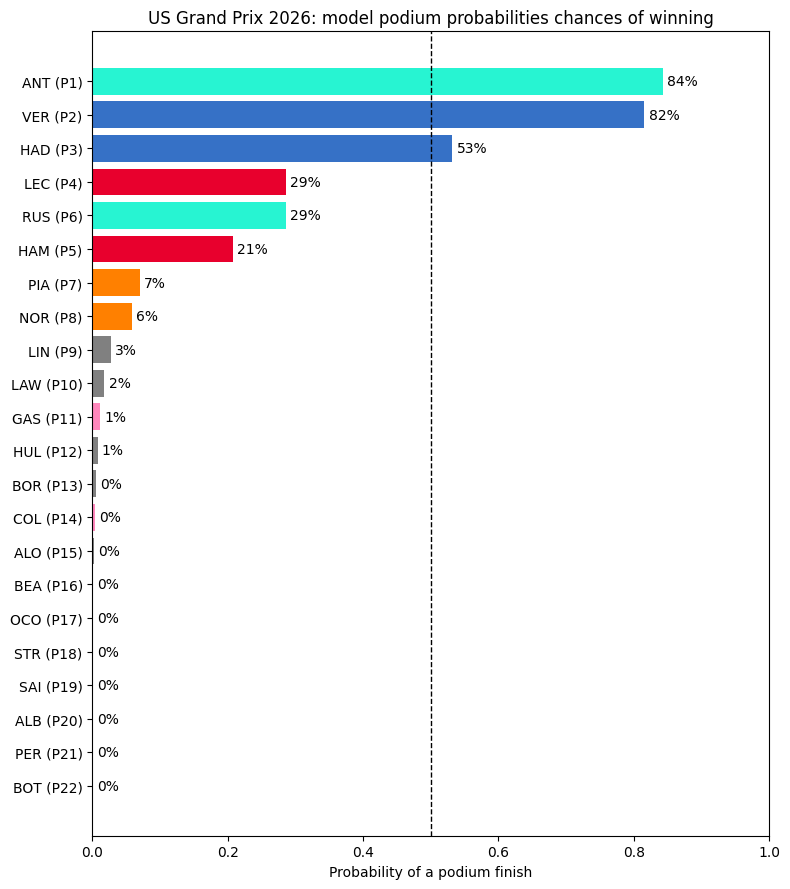

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
TEAM_COLORS = {
    'Mercedes': '#27F4D2', 'Red Bull': '#3671C6', 'Ferrari': '#E8002D',
    'McLaren': '#FF8000', 'Alpine F1 Team': '#FF87BC',
}

plot_df = out.sort_values('prob').copy()
plot_df['label'] = (plot_df['Abbreviation'] + ' (P'+ plot_df['grid'].astype(int).astype(str) + ')')
colors = plot_df['TeamName'].map(TEAM_COLORS).fillna('grey')
fig, ax = plt.subplots(figsize=(8, 9))
bars = ax.barh(plot_df['label'], plot_df['prob'], color=colors)
ax.bar_label(bars, labels=[f'{p:.0%}' for p in plot_df['prob']], padding=3)
ax.axvline(0.5, linestyle='--', color='black', linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel('Probability of a podium finish')
ax.set_title('US Grand Prix 2026: model podium probabilities chances of winning')
plt.tight_layout()
plt.savefig('us_gp_2026_prediction.png', dpi=150)
plt.show()
